<a href="https://colab.research.google.com/github/jamalla/reading-assistant-agent/blob/main/notebooks/01_data_check.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Data check — Jamalon Arabic Books
**Reading Assistant Agent — Lesson 1**

Before any code trusts a dataset, we *look* at it. This notebook checks the
[Jamalon Arabic Books Dataset](https://www.kaggle.com/datasets/dareenalharthi/jamalon-arabic-books-dataset)
(Kaggle, by Dareen Alharthi) and answers five questions:

1. What does a row look like?
2. How many books have **no description**? (useless for search)
3. How are books spread across **categories**?
4. Is there hidden **text corruption** (Arabic presentation forms)?
5. What **gaps and duplicates** exist?

The answers decide the rules in `build_books.py`.

In [1]:
# Setup: Arabic text needs reshaping + right-to-left ordering to show correctly in charts
!pip install -q arabic-reshaper python-bidi

import re, unicodedata, zipfile, glob, os
import pandas as pd
import matplotlib.pyplot as plt
import arabic_reshaper
try:
    from bidi import get_display            # python-bidi >= 0.5
except ImportError:
    from bidi.algorithm import get_display  # older python-bidi

def ar(text):
    """Make Arabic readable in matplotlib (joined letters, right-to-left)."""
    return get_display(arabic_reshaper.reshape(str(text)))

pd.set_option("display.max_colwidth", 80)
print("ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 1.9 MB/s eta 0:00:00
ready


## Step 1 · Upload the dataset
Run the cell and pick the zip you downloaded from Kaggle (or the CSV itself).

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()          # opens a file picker in Colab
except ImportError:
    uploaded = {}                      # running outside Colab: use files already here

for name in list(uploaded) + glob.glob("*.zip"):
    if name.endswith(".zip"):
        zipfile.ZipFile(name).extractall(".")

CSV = "jamalon dataset.csv"
print(CSV, "found:", os.path.exists(CSV), "|", round(os.path.getsize(CSV) / 1e6, 2), "MB")

Saving jamalon dataset.csv.zip to jamalon dataset.csv.zip
jamalon dataset.csv found: True | 6.99 MB


## Step 2 · First look

In [3]:
df = pd.read_csv(CSV, encoding="utf-8-sig", keep_default_na=False)  # keep the text "None" visible
print(df.shape[0], "rows x", df.shape[1], "columns")
df.head(3)

8986 rows x 11 columns


,Unnamed: 0,Title,Author,Description,Pages,Publication year,Publisher,Cover,Category,Subcategory,Price
0,0,فى فقه الصراع على القدس وفلسطين,محمد عمارة,الإسلامية كانت القدس رمز الصراع وبوابة الانتصار وفى كل مراحل هذا الصراع تشا...,180,2006,دار الشروق – مصر,غلاف ورقي,الأدب والخيال,الأدب الإسلامي,15.0
1,1,الرد على شبهات المستشرقين في السيرة النبوية(3),محمد بن عبد الرزاق اسود,None,86,2017,دار طيبة للنشر والتوزيع,غلاف ورقي,الأدب والخيال,الأدب الإسلامي,15.0
2,2,القصص التربوية عند الشيخ محمد تقي فلسفي,لطيف الراشدي,None,420,0,دار الكاتب العربي للطباعة والنشر,غلاف كرتوني,الأدب والخيال,الأدب الإسلامي,37.5


## Step 3 · Missing descriptions
Search works on the description. A book without one is invisible to the recommender.
Careful: missing values hide as the **text** `"None"`, not only as empty cells.

In [4]:
MISSING = {"", "none", "null", "nan", "لا يوجد"}

def is_missing(value):
    return pd.isna(value) or str(value).strip().lower() in MISSING

df["has_description"] = ~df["Description"].apply(is_missing)
missing = (~df["has_description"]).sum()
print(f"no description: {missing} of {len(df)} books ({missing / len(df):.0%})")
print("of which literally the text 'None':", (df["Description"].astype(str).str.strip() == "None").sum())

no description: 4543 of 8986 books (51%)
of which literally the text 'None': 3969


## Step 4 · Categories

,all books,with description
Category,,
الأدب والخيال,1217,638
الأسرة والطفل,710,403
الاقتصاد والأعمال,928,456
التاريخ والجغرافيا,322,137
الرياضة والتسلية,174,69
السير والمذكرات,478,255
الشرع والقانون,85,33
الصحافة والإعلام,904,279
العلوم والطبيعة,870,434


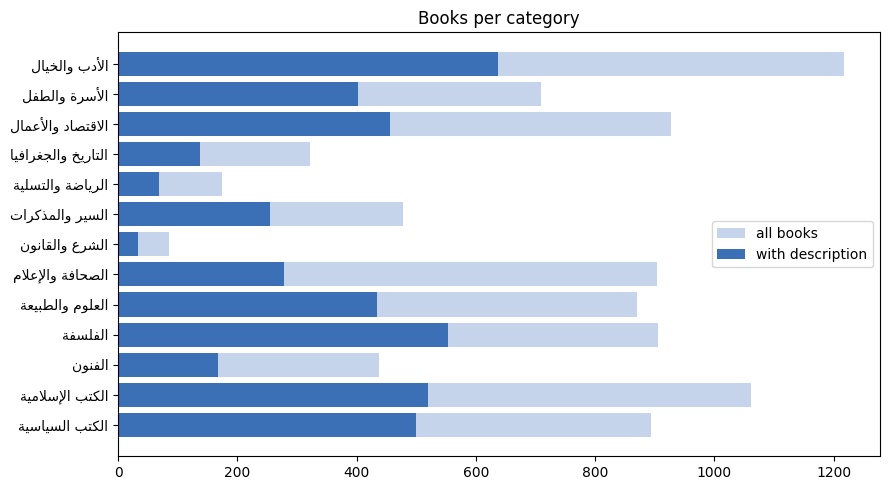

In [5]:
counts = df["Category"].value_counts()
with_desc = df[df["has_description"]]["Category"].value_counts()
table = pd.DataFrame({"all books": counts, "with description": with_desc}).fillna(0).astype(int)
display(table)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([ar(c) for c in table.index], table["all books"], color="#c5d4ea", label="all books")
ax.barh([ar(c) for c in table.index], table["with description"], color="#3b6fb6", label="with description")
ax.invert_yaxis()
ax.set_title("Books per category")
ax.legend()
plt.tight_layout()
plt.show()

## Step 5 · Hidden corruption: Arabic presentation forms
Some descriptions use *presentation form* code points (`U+FB50–U+FEFF`). They **look identical**
on screen but are different characters, so a search for «مذكرات» would never match «ﻣﺬﻛﺮات».
Unicode **NFKC** normalization converts them back to normal letters.

In [6]:
PRESENTATION = re.compile("[\uFB50-\uFDFF\uFE70-\uFEFF]")
desc = df.loc[df["has_description"], "Description"].astype(str)
bad = desc[desc.str.contains(PRESENTATION)]
print(len(bad), "descriptions use presentation forms")

before = bad.iloc[0][:60]
after = unicodedata.normalize("NFKC", before)
print("BEFORE:", before)
print("AFTER :", after)
print("look the same, but equal?", before == after)
print("search 'مذكرات' finds it?  before:", "مذكرات" in before, "| after:", "مذكرات" in after)

8 descriptions use presentation forms
BEFORE:  ھﺬه ﻣﺬﻛﺮات ﻓﻲ اﻷدب اﻹﺳﻼﻣﻲ، وﺿﻌﮫﺎ اﻟﻤﺆﻟﻒ ﻟﻄﻼﺑﻪ ﻓﻲ اﻟﻤﻌﺎھﺪ اﻟ
AFTER :  ھذه مذكرات في الأدب الإسلامي، وضعھا المؤلف لطلابه في المعاھد ال
look the same, but equal? False
search 'مذكرات' finds it?  before: False | after: True


In [7]:
# Diagnostic: which Unicode ranges appear, and in how many descriptions?
all_desc = df["Description"].astype(str)
for name, pattern in {
    "Arabic Presentation Forms-A  U+FB50-U+FDFF": "[\uFB50-\uFDFF]",
    "Arabic Presentation Forms-B  U+FE70-U+FEFE": "[\uFE70-\uFEFE]",
    "Zero-width no-break space   U+FEFF": "\uFEFF",
}.items():
    print(f"{all_desc.str.contains(pattern).sum():5d}  {name}")

    5  Arabic Presentation Forms-A  U+FB50-U+FDFF
    8  Arabic Presentation Forms-B  U+FE70-U+FEFE
    0  Zero-width no-break space   U+FEFF


## Step 6 · Description length
Very short descriptions ("كتاب رائع") carry no signal. How many are long enough to search?

count    4443.0
mean      609.0
std       630.0
min         5.0
25%       365.0
50%       369.0
75%       574.0
max      8077.0
Name: Description, dtype: float64

at least 100 characters: 4350


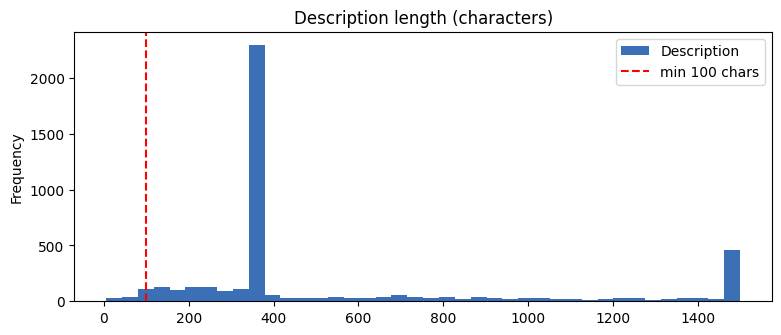

In [8]:
lengths = desc.apply(lambda t: len(unicodedata.normalize("NFKC", t).strip()))
print(lengths.describe().round(0))
print("\nat least 100 characters:", (lengths >= 100).sum())

lengths.clip(upper=1500).plot.hist(bins=40, figsize=(9, 3.5), color="#3b6fb6", title="Description length (characters)")
plt.axvline(100, color="red", linestyle="--", label="min 100 chars")
plt.legend()
plt.show()

## Step 7 · Duplicates
Same title twice = the agent could recommend "two" books that are really one.
Multi-volume sets (`(1)`, `(2)`, …) are a related trap.

In [9]:
titles = df["Title"].astype(str).apply(lambda t: unicodedata.normalize("NFKC", t).strip())
dupes = titles[titles.duplicated(keep=False)]
print("rows sharing a title:", len(dupes), "| distinct titles involved:", dupes.nunique())
print(dupes.value_counts().head(5))

volumes = titles[titles.str.contains(r"\(\d+\)|ج\s*\d|الجزء")]
print("\nlook like volumes of a series:", len(volumes))
print(volumes.head(5).to_list())

rows sharing a title: 1517 | distinct titles involved: 662
Title
دور المنظمات الدولية غير الحكومية في عمليات بناء السلام في إفريقيا بعد انتهاء الحرب الباردة    13
صاحب الظل الطويل                                                                               12
البؤساء                                                                                        11
أوروبا والوطن العربي                                                                           11
الإرهاب العالمي والتطرف                                                                        11
Name: count, dtype: int64

look like volumes of a series: 127
['الرد على شبهات المستشرقين في السيرة النبوية(3)', 'الطب الوقائي في السنة النبوية (1)', 'رعاية الحيوان في السنة النبوية (6)', 'رعاية البيئة في السنة النبوية (4)', 'تعزيز البعد الإنساني في العمل البلدي الرياض (1)']


## Step 8 · Coverage gaps: children's stories?
A recommender can only recommend what exists. Let's look inside «الأسرة والطفل» (family & child).

In [10]:
family = df[df["Category"] == "الأسرة والطفل"]
print("subcategories in الأسرة والطفل:")
display(family["Subcategory"].value_counts().head(10).to_frame("books"))

stories = df[df["Title"].astype(str).str.contains("قصص|قصة|حكايات") & df["has_description"]]
print("titles with قصص / قصة / حكايات (with description):", len(stories))
display(stories[["Title", "Category", "Subcategory"]].head(8))

subcategories in الأسرة والطفل:


,books
Subcategory,
شؤون المرأة,207
الأطفال,205
تربية الأطفال,185
الجمال,45
التربية الجنسية,37
العلاقات الزوجية,29
الأزياء,2


titles with قصص / قصة / حكايات (with description): 60


,Title,Category,Subcategory
21,قصة كاملة... لم يؤلفها بشر,الأدب والخيال,الأدب الإسلامي
47,عروس تزف إلى قبرها وقصص أخرى,الأدب والخيال,الأدب الإسلامي
127,قصة الأندلس من الفتح إلى السقوط1,الأدب والخيال,الأدب الإسلامي
214,قصة كاملة... لم يؤلفها بشر,الأدب والخيال,الأعمال الكاملة
240,عروس تزف إلى قبرها وقصص أخرى,الأدب والخيال,الأعمال الكاملة
320,قصة الأندلس من الفتح إلى السقوط1,الأدب والخيال,الأعمال الكاملة
429,الزلة الكبرى وقصص أخرى,الأدب والخيال,الروايات
548,حكايات نجيع,الأدب والخيال,الروايات


## Step 9 · Decision: what `build_books.py` keeps
Apply the exact same rules as `build_books.py`: NFKC clean → description ≥ 100 chars → drop duplicate titles.
The number below must match what `build_books.py` prints in CloudShell.

In [11]:
def clean(text):
    text = re.sub(r"\s+", " ", unicodedata.normalize("NFKC", "" if pd.isna(text) else str(text))).strip()
    return "" if text.lower() in MISSING else text

seen, usable = set(), 0
for _, row in df.iterrows():
    title, description = clean(row["Title"]), clean(row["Description"])
    if not title or len(description) < 100 or title in seen:
        continue
    seen.add(title)
    usable += 1

print(f"usable books: {usable} of {len(df)}  →  build_books.py samples 200 of these, ~15 per category")

usable books: 3964 of 8986  →  build_books.py samples 200 of these, ~15 per category
